# Lab Assignment

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import classification_report, confusion_matrix

# rndm
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# 1. Load Inspect MNIST
(X_train_raw, y_train), (X_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

# Flatten 28x28 images into 784-dimensional feature vectors
X_train_flat = X_train_raw.reshape(-1, 784).astype("float32")
X_test_flat = X_test_raw.reshape(-1, 784).astype("float32")

print(f"Training shape: {X_train_flat.shape}, Test shape: {X_test_flat.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training shape: (60000, 784), Test shape: (10000, 784)


In [3]:
# 2. Preprocessing
# Method A: Normalization (Min-Max scaling to [0, 1])
X_train_norm = X_train_flat / 255.0
X_test_norm = X_test_flat / 255.0

# Method B: Standardization (mean = 0, std = 1)
mean = X_train_flat.mean(axis=0)
std = X_train_flat.std(axis=0) + 1e-7  # avoid division by zero on blank border pixels
X_train_std = (X_train_flat - mean) / std
X_test_std = (X_test_flat - mean) / std

In [4]:
# 3. Feature selection, variance thresholding
selector = VarianceThreshold(threshold=0.01)
X_train_fs = selector.fit_transform(X_train_norm)
X_test_fs = selector.transform(X_test_norm)

print(f"Original features: {X_train_norm.shape[1]} -> Selected features: {X_train_fs.shape[1]}")

Original features: 784 -> Selected features: 444


In [5]:
# 4. Modular ANN buildr
def build_ann(input_dim, hidden_units=(128, 64), activation="relu", dropout_rate=0.0, use_bn=False):
    model = models.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    for units in hidden_units:
        model.add(layers.Dense(units))
        if use_bn:
            model.add(layers.BatchNormalization())

        if activation == "leaky_relu":
            model.add(layers.LeakyReLU(negative_slope=0.1))
        else:
            model.add(layers.Activation(activation))

        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))

    # Output layer: 10 classes (digits 0-9) with Softmax
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [6]:
# 5. RUN EXPLORATION EXPERIMENTS
experiments = [
    {
        "name": "1. Baseline (Norm + ReLU + 128-64)",
        "X_tr": X_train_norm, "X_te": X_test_norm,
        "units": (128, 64), "act": "relu", "drop": 0.0, "bn": False
    },
    {
        "name": "2. Preprocessing: Standardization",
        "X_tr": X_train_std, "X_te": X_test_std,
        "units": (128, 64), "act": "relu", "drop": 0.0, "bn": False
    },
    {
        "name": "3. Feature Selection (VarThreshold)",
        "X_tr": X_train_fs, "X_te": X_test_fs,
        "units": (128, 64), "act": "relu", "drop": 0.0, "bn": False
    },
    {
        "name": "4. Activation: Tanh",
        "X_tr": X_train_norm, "X_te": X_test_norm,
        "units": (128, 64), "act": "tanh", "drop": 0.0, "bn": False
    },
    {
        "name": "5. Activation: LeakyReLU",
        "X_tr": X_train_norm, "X_te": X_test_norm,
        "units": (128, 64), "act": "leaky_relu", "drop": 0.0, "bn": False
    },
    {
        "name": "6. Deeper Arch + Dropout + BatchNorm",
        "X_tr": X_train_norm, "X_te": X_test_norm,
        "units": (256, 128, 64), "act": "relu", "drop": 0.2, "bn": True
    },
]

results = []
best_model = None
best_acc = 0.0
best_X_test = None
best_history = None

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

for exp in experiments:
    print(f"\n--- Running: {exp['name']} ---")
    model = build_ann(
        input_dim=exp["X_tr"].shape[1],
        hidden_units=exp["units"],
        activation=exp["act"],
        dropout_rate=exp["drop"],
        use_bn=exp["bn"]
    )

    history = model.fit(
        exp["X_tr"], y_train,
        validation_split=0.1,
        epochs=15,
        batch_size=128,
        callbacks=[early_stop],
        verbose=0
    )

    test_loss, test_acc = model.evaluate(exp["X_te"], y_test, verbose=0)
    results.append({
        "Experiment": exp["name"],
        "Input Features": exp["X_tr"].shape[1],
        "Epochs Run": len(history.history["loss"]),
        "Val Accuracy": max(history.history["val_accuracy"]),
        "Test Accuracy": test_acc,
        "Test Loss": test_loss
    })
    print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")

    if test_acc > best_acc:
        best_acc = test_acc
        best_model = model
        best_X_test = exp["X_te"]
        best_history = history

# Display Comparison Table
results_df = pd.DataFrame(results)
print("\n=== EXPERIMENT SUMMARY ===")
print(results_df.to_string(index=False))





--- Running: 1. Baseline (Norm + ReLU + 128-64) ---
Test Accuracy: 0.9738 | Test Loss: 0.0874

--- Running: 2. Preprocessing: Standardization ---
Test Accuracy: 0.9545 | Test Loss: 1228.5844

--- Running: 3. Feature Selection (VarThreshold) ---
Test Accuracy: 0.9480 | Test Loss: 0.1704

--- Running: 4. Activation: Tanh ---
Test Accuracy: 0.9404 | Test Loss: 0.1996

--- Running: 5. Activation: LeakyReLU ---
Test Accuracy: 0.9478 | Test Loss: 0.1745

--- Running: 6. Deeper Arch + Dropout + BatchNorm ---
Test Accuracy: 0.9812 | Test Loss: 0.0676

=== EXPERIMENT SUMMARY ===
                          Experiment  Input Features  Epochs Run  Val Accuracy  Test Accuracy   Test Loss
  1. Baseline (Norm + ReLU + 128-64)             784          10      0.975667         0.9738    0.087416
   2. Preprocessing: Standardization             784           3      0.969167         0.9545 1228.584351
 3. Feature Selection (VarThreshold)             444           3      0.972000         0.9480    0.17038


=== CLASSIFICATION REPORT (BEST MODEL) ===
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.99      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.99      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.99      0.98      0.98       958
           7       0.97      0.98      0.98      1028
           8       0.98      0.97      0.97       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



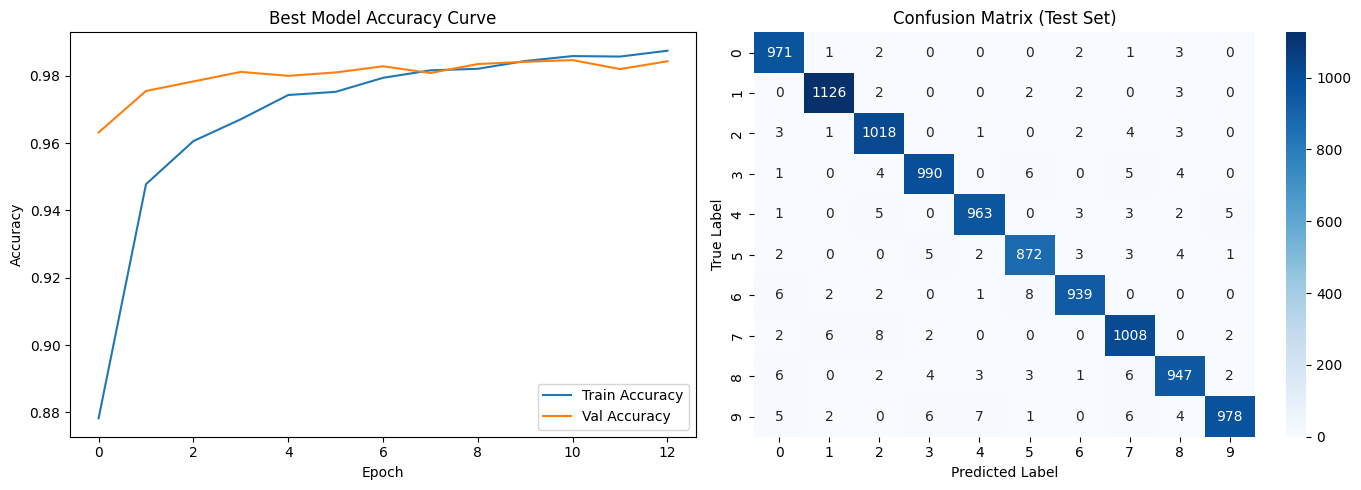

In [7]:
# 6. FINAL EVALUATION OF BEST MODEL
y_pred = np.argmax(best_model.predict(best_X_test, verbose=0), axis=1)

print("\n=== CLASSIFICATION REPORT (BEST MODEL) ===")
print(classification_report(y_test, y_pred))

# Plot Training Curves & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curve
axes[0].plot(best_history.history["accuracy"], label="Train Accuracy")
axes[0].plot(best_history.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("Best Model Accuracy Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Confusion Matrix (Test Set)")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()